In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
from Experiment_4.ParametricWMTask import generate_trials
import pandas as pd
import matplotlib
import networkx as nx
import torch
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
from Experiment_4.net import *
import os
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .75

In [3]:
def compute_var(variance,n):
    return np.sum(variance[n:])

def compute_p(k, null_k):
    return (np.sum(null_k<k)/len(null_k))

In [5]:
df_list = []
for filename in os.listdir('Experiment_4/Results_4'):
    f = os.path.join('Experiment_4/Results_4', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True) 
original_df = original_df[original_df.mse_z<.035]
original_df = original_df[original_df.linear_error>.25]
##original_df_act = original_df_act[original_df_act.sigma_rec==0]
#original_df_act = original_df_act[original_df_act.lr==0.005]
#original_df = original_df[original_df.n==100]
#original_df_act = original_df_act[original_df_act.beta==1.4]
#original_df.lvar = original_df.lvar.astype(float)

In [6]:

k = 4
df = original_df.copy()
#df['var'] = df.variance.apply(lambda x: compute_var(x,k))
#df['var_pre'] = df.variance.apply(lambda x: compute_var(x,k-1))
#df['k_inertia'] = df.inertia.apply(lambda x: x[k-1])
#df = df[df.dim==k]
df.sort_values('pca_error', ascending=True)

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,lambda_std,lvar_pca,lvar_kmeans,lvar_lds,n,dim,null_kmeans_error,pca_error,kmeans_error,linear_error
31329,5kDyzMOu,"[[0.0, -0.03371271, -0.11506604, 0.043642376, ...","[[0.34092256, 0.31322435], [0.2918567, -0.3173...","[[0.11348082, 0.19138847, -0.057611004, 0.1899...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.006989,1000,0.0,0.0,0.0,...,0.4,-0.263665,0.784760,-0.263665,100,4,0.149714,0.000014,0.002523,0.264160
41249,dyrEEEvx,"[[0.0, 0.01866028, -0.2222029, -0.06215668, -0...","[[-0.2575956, 0.2638666], [0.27070072, -0.2509...","[[-0.08104916, 0.10896571, 0.18874364, -0.0403...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.018664,1000,0.0,0.0,0.0,...,0.4,0.042813,0.784760,-0.263665,100,4,0.161259,0.000015,0.002871,0.267710
61887,UUe1LGe8,"[[0.0, -0.024396623, -0.07527705, 0.07826816, ...","[[-0.05030835, 0.3431337], [0.42912355, 0.1035...","[[0.024527036, 0.14326228, 0.019499535, -0.131...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.007438,1000,0.0,0.0,0.0,...,0.4,-0.088587,0.545559,-0.127427,100,4,0.191164,0.000019,0.003200,0.260292
15290,4l8YbJSe,"[[0.0, 0.07025152, -0.025345394, -0.0042268317...","[[0.5564818, 0.29903233], [0.55537, 0.30250138...","[[0.074670106, 0.066202305, -0.15323447, -0.02...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.020112,1000,0.0,0.0,0.0,...,0.4,-0.183298,1.128838,-0.379269,100,4,0.207836,0.000023,0.003300,0.288771
18608,4x4AKdap,"[[0.0, -0.040306948, -0.01921776, 0.029828599,...","[[0.101563334, -0.20288827], [0.3426768, 0.282...","[[0.004886231, 0.11557899, 0.029489672, 0.0067...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.030248,1000,0.0,0.0,0.0,...,0.4,-0.042813,1.128838,-0.183298,100,4,0.155740,0.000025,0.003771,0.265199
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8774,ZfO9oGSH,"[[0.0, -0.3188777, -0.16024911, -0.09421297, 0...","[[-0.6633033, 0.04836878], [0.21273498, -0.326...","[[-0.17648956, 0.22823243, 0.1644276, 0.039044...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.024700,1000,0.0,0.0,0.0,...,0.4,-6.951928,-0.010000,-1.623777,100,4,0.783173,0.799517,0.783153,0.857761
29973,SvQVtqlW,"[[0.0, -0.32929194, 0.05379206, -0.24806055, -...","[[-0.39171588, -0.42157257], [-0.02040315, -0....","[[0.071340635, 0.25424635, 0.071383305, 0.0553...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.022331,1000,0.0,0.0,0.0,...,0.4,-6.951928,1.128838,-1.128838,100,4,0.767074,0.799890,0.761424,0.841929
61330,2oKMTOqq,"[[0.0, -0.08881658, 0.006311945, -0.06506739, ...","[[-0.2831704, 0.44468904], [0.2021614, 0.39993...","[[-0.14200313, 0.11118589, 0.014293666, -0.002...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.021288,1000,0.0,0.0,0.0,...,0.4,-4.832930,0.020691,-0.379269,100,4,0.782203,0.800317,0.781744,0.841210
52772,Z1kByLkK,"[[0.0, 0.016852789, 0.0172477, -0.26292482, -0...","[[0.63073075, 0.24304606], [0.42322126, 0.1832...","[[0.092533864, 0.13815299, 0.094033994, -0.352...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.018730,1000,0.0,0.0,0.0,...,0.4,-3.359818,0.042813,-0.784760,100,4,0.779976,0.801199,0.778705,0.848159


In [179]:
.23*.24

0.0552

In [160]:
np.sqrt(.0007)

0.026457513110645904

4
1.7924338e-05


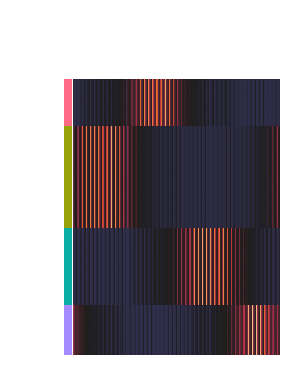

In [8]:
## CLUSTERED RESPONSE MATRIX        
#_,k = compute_k(responses,5,25,.05)

## RESPONSE MATRIX
model_data = df[df.model_id == '5kDyzMOu']
net = Net(n=100,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2).float()
net.sigma_rec = 0.
net.sigma_in = 0.1

#aACTIVATION
net.activation = torch.nn.Softplus(beta = model_data['beta'].item())

u, z, mask, conditions  = generate_trials(
                            n_trials=25)
x = net(u).detach().cpu().numpy()

#activity_std = torch.std(torch.mean(x, dim=[0, 1])).detach().cpu().numpy() / torch.mean(torch.mean(x, dim=[0, 1])).detach().cpu().numpy()
# activity_std = torch.std(torch.mean(x, dim=[0, 1])).detach().cpu().numpy() / torch.mean(torch.mean(x, dim=[0, 1])).detach().cpu().numpy()
# 
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()

#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

#responses = responses[np.mean(responses, axis=1) >.025, :]


responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]


k = model_data.dim.values[0]
print(k)
import matplotlib
clustering = KMeans(n_clusters=k, n_init=20).fit(responses)
total_variance = np.sum((responses.T - np.mean(responses.T, axis=0, keepdims=True)) ** 2)
print(clustering.inertia_/total_variance)
labels = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort, :]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size, s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(), network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)), row_cluster=False, col_cluster=False, row_colors=row_colors,
                   figsize=(3, 3.75), xticklabels=False, yticklabels=False,center=0,cbar_pos=None)
ax = g.ax_heatmap

g.savefig('/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Figures/response_matrix.jpg',
          format='jpeg',
          dpi=450,
          bbox_inches='tight'
          )

In [7]:
y = net.linear_forward(u).detach().numpy()

<Axes: >

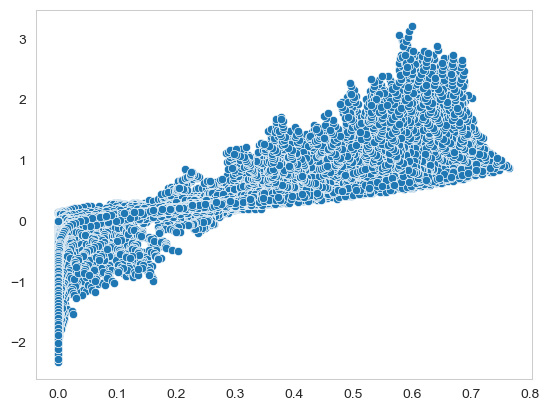

In [8]:
plt.figure()
sns.scatterplot(x = x[:,:,5].flatten(),y = y[:,:,5].flatten())

In [45]:
y = net.linear_forward(u)
x = net(u)
x_centered = x - torch.mean(x, dim=[0, 1],keepdim=True)

y = net.linear_forward(u)
y_centered = y - torch.mean(y, dim=[0, 1],keepdim=True)


numerator = torch.sum(x_centered * y_centered,dim=[0,1])

sigma_x = torch.sqrt(torch.sum(x_centered**2,dim=[0,1]))
sigma_y = torch.sqrt(torch.sum(y_centered**2,dim=[0,1]))

correlation = 1 - (numerator / sigma_x/ sigma_y)**2

<Axes: ylabel='Count'>

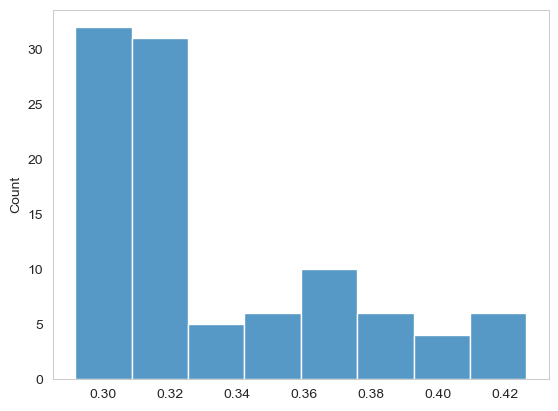

In [46]:
plt.figure()
sns.histplot(correlation.detach())

In [228]:
torch.mean((numerator / sigma_x/ sigma_y)**2)

tensor(0.6721, grad_fn=<MeanBackward0>)

In [188]:
from scipy import stats
stats.pearsonr(x[:,:,3].flatten(), y[:,:,3].flatten())

PearsonRResult(statistic=0.8690103296142699, pvalue=0.0)

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_85595/3975737725.py:43: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  H = w @ U


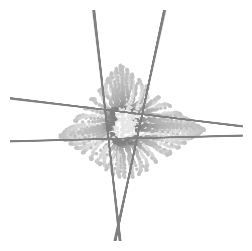

In [9]:
# HYPERPLANES
fig = plt.figure(figsize=(3,3))
gs = gridspec.GridSpec(1,1)
palette = sns.husl_palette(s=1,n_colors=75)

u, z, mask, conditions  = generate_trials(
                            n_trials=25)

ax=fig.add_subplot(gs[0,0])
model_data = original_df[original_df.model_id == '5kDyzMOu']
net = Net(n=100,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2).float()

# ACTIVATION
#net.activation = torch.nn.Softplus(beta=model_data['beta'].item())


net.sigma_in = 0.1
net.sigma_rec = 0

x = net.forward(u)
n_neurons = x.shape[2]
#Restrict to act
#  x = x[:,:,n_active]
pca = PCA()
pca.fit(x.detach().numpy().reshape(-1,x.shape[2]))

U = pca.components_[:2,:].T
#U = latent_net.module_.q[:2,:].t().detach()
w = net.recurrent_layer.weight.data
# w = w[n_active,:]
# w = w[:,n_active]
#w = w-np.eye(50)
w_in = net.input_layer.weight.data

b = net.recurrent_layer.bias.data

H = w @ U 
#H = H[sort,:]
proj_rates = pca.transform(x.detach().reshape(-1,x.shape[2]))
proj_rates = proj_rates.reshape(-1,x.shape[1],x.shape[2])


lim =5
xx,yy = np.linspace(-lim,lim), np.linspace(-lim,lim)
x,y = np.meshgrid(xx,yy)
for i in range(n_neurons):
#for i in np.argwhere(labels==0):

    magnitude = np.linalg.norm(H[i,:].numpy())

    #ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors=network_pal.as_hex()[labels[i]],linewidths=.75)
    ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors='gray',linewidths=.75,alpha=.5)

#for i in range(n_neurons):
# for i in np.argwhere(labels==0):
# 
#     magnitude = np.linalg.norm(H[i,:].numpy())
# 
#     #ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors=network_pal.as_hex()[labels[i]],linewidths=.75)
#     ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],color='gray',linewidths=.75,alpha=1)


# for i in np.argwhere(labels==1):
# 
#     magnitude = np.linalg.norm(H[i,:].numpy())
# 
#     #ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors=network_pal.as_hex()[labels[i]],linewidths=.75)
#     ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],color='gray',linewidths=.75)


# for i in range(25):
#     ax.plot(proj_rates[i,57:,0],proj_rates[i,57:,1],lw=1)

x = net.forward(u).detach().cpu().numpy()
pca = PCA()
pca.fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], x.shape[2])
rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()


#sns.scatterplot(data=new_df,x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=1,alpha=.1,edgecolor=None)
palette = sns.husl_palette(n_colors = 25,s = 1)
# sns.scatterplot(data=new_df_mean[new_df_mean.t<30], x='z_1', y='z_2', ax=ax, legend=False, s=3, alpha=.5,color='gray')
# # sns.scatterplot(data=new_df_mean[new_df_mean.t==74], x='z_1', y='z_2', ax=ax, legend=False, s=10, alpha=1, hue='theta',palette=palette)
# sns.scatterplot(data=new_df_mean[new_df_mean.t>70],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
sns.scatterplot(data=new_df_mean,x='z_1',y='z_2',ax=ax,legend=False,s=5,alpha=1,edgecolor=None,hue = 't',palette=sns.light_palette("gray",as_cmap=True))
# sns.scatterplot(data=new_df[new_df.t>70],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=.5,edgecolor=None,palette = palette)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
# ax.set_xlim(-16,16)
# ax.set_ylim(-8,8)

fig.savefig('Figures/Fig1a.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight',
            transparent=True)


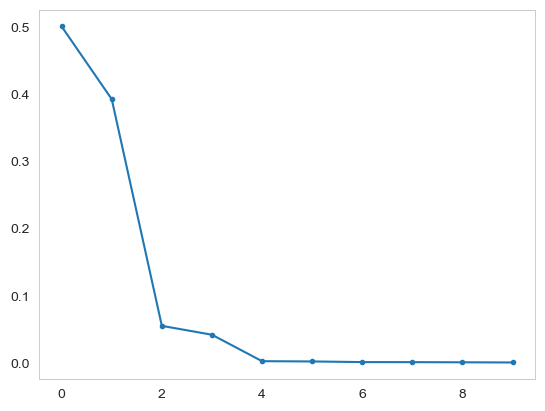

In [98]:
plt.figure()
plt.plot(pca.explained_variance_ratio_[:10],marker='.')

In [7]:
lds = LDS(n=6)
x = net.forward(u)
lds.fit(u,x.detach(),epochs = 1000)
#y = net.linear_forward(u)
y = lds.output_layer(lds(u))

In [8]:
net.linear_error(y,x)

tensor(0.0489, grad_fn=<MeanBackward0>)

<Axes: xlabel='None', ylabel='None'>

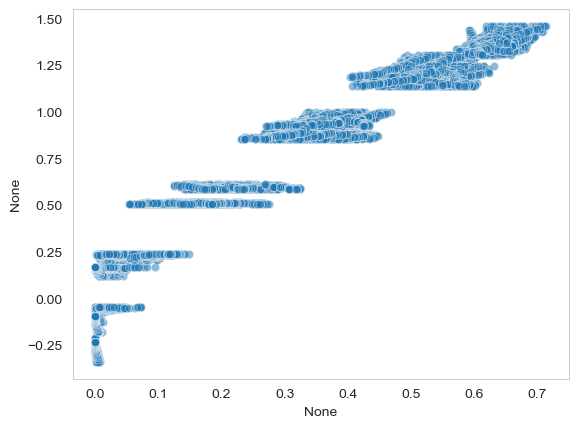

In [9]:
plt.figure()
sns.scatterplot(x = x[:,30:,3].detach().flatten(),y = y[:,30:,3].detach().flatten(),alpha=.5)

In [14]:
from scipy import stats
stats.pearsonr(x[:,:,3].detach().flatten(), y[:,:,3].detach().flatten())

PearsonRResult(statistic=-0.97177317925638, pvalue=0.0)

<Axes: >

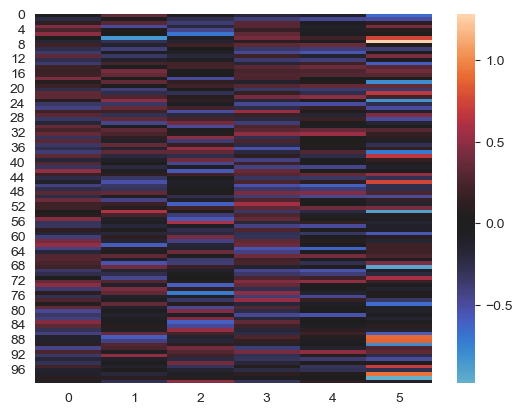

In [25]:
plt.figure()
sns.heatmap(lds.output_layer.weight.data.detach(),center=0)

In [265]:
matrix = np.zeros((75,75))
A = net.recurrent_layer.weight.data

for neuron in range(100):

    a = torch.tensor(H[None,neuron,:]).float()
    
    U = torch.tensor(U).float()
    
    neuron_matrix = np.zeros((75,75))
    x_vals = np.linspace(-5.5,5.5,75)
    y_vals = np.linspace(5.5,-5.5,75)
    for i in range(75):
        for j in range(75):
            x = x_vals[j]
            y = y_vals[i]
            v = torch.tensor([[x],[y]]).float()
            f = - v + U.t() @torch.nn.ReLU()(A @U@v+0.2)
            c = (f.t() @ a.t())**2 * np.exp(net.beta * ((a @ v) +.2))/ ((1+ np.exp(net.beta * ((a @ v) +.2)))**2)
            #c = np.exp(100 * ((a @ v) +.2))/ ((1+ np.exp(100 * ((a @ v) +.2)))**2)
            neuron_matrix[i,j] = c.item()
    matrix +=neuron_matrix**2
matrix = np.sqrt(matrix)
        

        # Compute f at point


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_50372/2719798225.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  a = torch.tensor(H[None,neuron,:]).float()
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_50372/2719798225.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  U = torch.tensor(U).float()


In [3]:
3 *3 *3 *4 *3

324

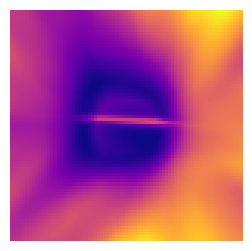

In [266]:
plt.figure(figsize = (3,3))
sns.heatmap(matrix,vmin=0,xticklabels=[],yticklabels=[],cmap = 'plasma',cbar = False)
plt.savefig('Figures/Fig1b.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight')

0.0037082060164944784


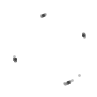

In [146]:
u, z, mask, conditions  = generate_trials(
                                    n_trials=100)


fig = plt.figure(figsize=(1,1))
gs = gridspec.GridSpec(1,1)
k = 4
ax=fig.add_subplot(gs[0,0])
model_data = original_df[original_df.model_id == 'cTPH2Ypu']
net = Net(n=100,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2).float()

# ACTIVATION
net.activation = torch.nn.Softplus(beta=model_data['beta'].item())


x = net(u).detach().cpu().numpy()


rows = []
for trial in range(u.shape[0]):
    rows.append({'trial': trial,
                 'theta': conditions[trial]['theta'],
                 'response': x[trial, :, :]})
model_df = pd.DataFrame(rows)
model_df = model_df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()

responses = np.stack(model_df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

# z_score
responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

#responses = .001 * (2*np.random.rand(responses.shape[0],responses.shape[1])-1)
total_variance = np.sum((responses - np.mean(responses, axis=0, keepdims=True)) ** 2)

clustering = KMeans(n_clusters=k,n_init='auto').fit(responses)
labels  = clustering.labels_
print(clustering.inertia_/total_variance)

#responses  = responses + .5*(2*np.random.rand(responses.shape[0],responses.shape[1])-1)

X = responses
y = labels
lda = PCA()

# parameters = {'tol':10**np.linspace(-2,-.5,25)}
# from sklearn.model_selection import GridSearchCV
# clf = GridSearchCV(lda, parameters,refit=True,error_score = np.nan,cv=5)
# clf.fit(X, y)
# lda = clf.best_estimator_
x_proj = lda.fit_transform(X)


    
centers_proj = lda.transform(clustering.cluster_centers_)
#scale = np.sum(PCA().fit(centers_proj).explained_variance_[:2])/100



#x_proj = x_proj + 1*(2*np.random.rand(x_proj.shape[0],x_proj.shape[1])-1)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)

lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)

sns.scatterplot(x=x_proj[np.argsort(labels), 0], y=x_proj[np.argsort(labels), 1], color='gray',s=3,alpha=.5,ax=ax,edgecolor=None)
sns.scatterplot(x=centers_proj[:, 0], y=centers_proj[:, 1], color='k',s=3,alpha=.5,ax=ax,edgecolor=None)

# Make axis pretty
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_xlabel("PC 1",fontsize=6)
ax.set_ylabel("PC 2",fontsize=6)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=6,bottom=False)
ax.yaxis.set_tick_params(labelsize=6,left=False)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
# ax.text(.5,-.2,r'$\sum_{i>3}\lambda_i = $'+' '+str(np.round(model_data['var'].item(),4) ), horizontalalignment='center',
# verticalalignment='center', transform=ax.transAxes,fontsize = 3)

plt.savefig('Figures/Fig1d.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight')


In [164]:
np.sum(PCA().fit(responses.T).explained_variance_ratio_[4:])

0.00062639214

In [165]:
clustering.inertia_/total_variance

0.0037082060164944784

In [166]:
.0037*.14

0.0005180000000000001

In [150]:
#responses = PCA(n_components =25).fit_transform(responses)
kmeans = KMeans(n_clusters=4,n_init='auto').fit(responses)
predicted_responses = np.zeros_like(responses)
for neuron in range(responses.shape[0]):
    predicted_responses[neuron,:] = kmeans.cluster_centers_[kmeans.labels_[neuron],:]
#total_variance = np.sum((responses.T - np.mean(responses.T, axis=0, keepdims=True)) ** 2)
errors = []
for condition in range(responses.shape[1]):
    x = responses[:, condition]
    x_centered = x - np.mean(x)

    y = predicted_responses[:, condition]
    y_centered = y - np.mean(y)

    numerator = np.sum(x_centered * y_centered)

    sigma_x = np.sqrt(np.sum(x_centered**2))
    sigma_y = np.sqrt(np.sum(y_centered**2))
    correlation = numerator / sigma_x / sigma_y
    errors.append(1-correlation**2)

<Axes: >

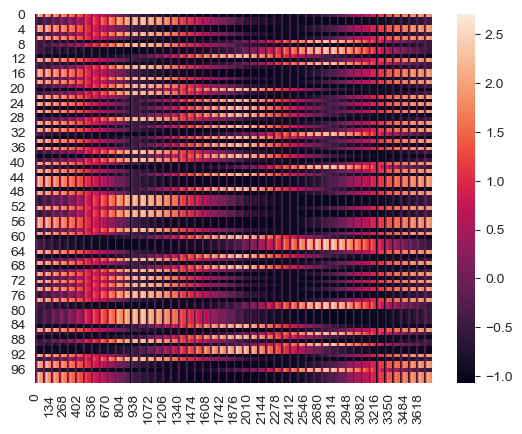

In [152]:
plt.figure()
sns.heatmap(predicted_responses)

<Axes: >

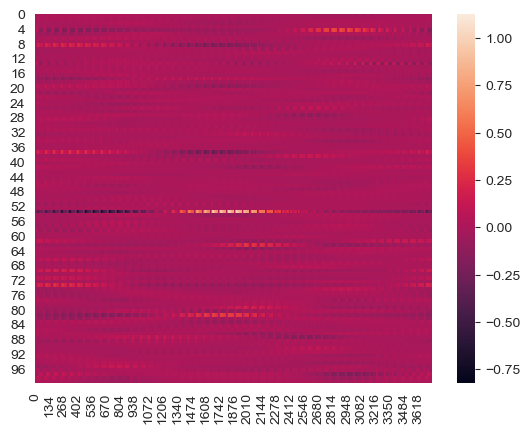

In [154]:
plt.figure()
sns.heatmap((responses-predicted_responses)

In [156]:
np.mean(np.sqrt((responses-predicted_responses)**2))

0.030081008

In [151]:
np.mean(errors)

0.021829739744366427

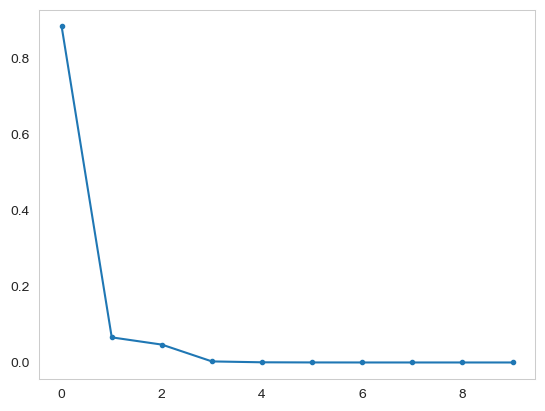

In [24]:
plt.figure()
plt.plot(pca.explained_variance_ratio_[:10],marker='.')

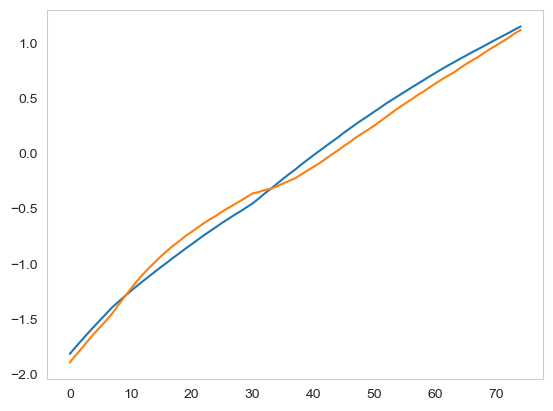

In [28]:
plt.figure()
plt.plot(clustering.cluster_centers_[0,75:150])
plt.plot(responses[2,75:150])

In [16]:
clustering.labels_

array([2, 0, 0, 2, 0, 2, 2, 3, 1, 0, 1, 1, 1, 2, 0, 1, 0, 3, 1, 3, 3, 1,
       3, 3, 1, 1, 3, 2, 0, 2, 1, 2, 2, 0, 3, 1, 1, 1, 0, 2, 3, 3, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 3, 0, 1, 1, 1, 0, 1, 1, 3, 1, 1, 1, 0, 2, 0,
       2, 2, 2, 3, 0, 2, 1, 0, 0, 0, 1, 0, 1, 1, 2, 0, 1, 2, 1, 1, 3, 0,
       0, 3, 3, 2, 3, 3, 1, 1, 0, 0, 2, 3], dtype=int32)

In [38]:
matrix.flatten()

array([nan, nan, nan, ..., nan, nan, nan])

In [15]:
H.shape,v.shape

(torch.Size([100, 2]), torch.Size([2, 1]))

<Axes: ylabel='Count'>

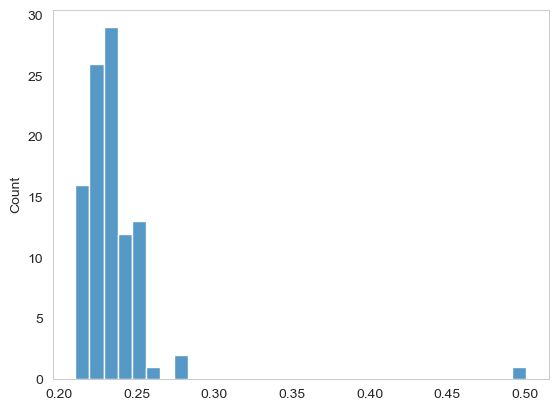

In [8]:
plt.figure()
sns.histplot(x = np.linalg.norm(H,axis=1))

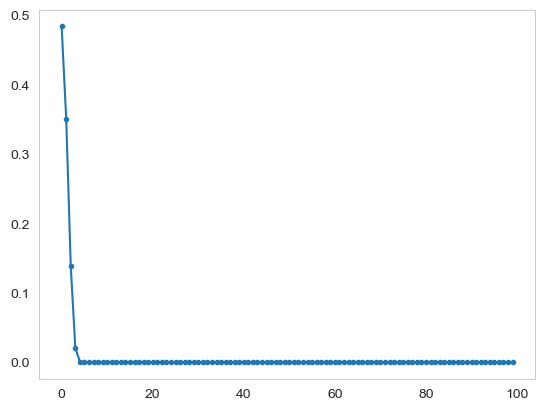

In [7]:
plt.figure()
plt.plot(pca.explained_variance_ratio_,marker = '.')

In [7]:
torch.mean(torch.linalg.norm(H, dim=[1]))

tensor(0.2319)

In [8]:
u, z, mask, conditions  = generate_trials(
                            n_trials=25)
net.sigma_in=0
net.sigma_rec = 0
dim = 4
x = net(u)
x = x - torch.mean(x, dim=[0, 1])
# u,s,v = torch.pca_lowrank(x.reshape(-1,x.shape[2]))
s,v = torch.linalg.eigh(torch.cov(x.reshape(-1, x.shape[2]).t()))
# Restrict A to subspace
a = net.recurrent_layer.weight.data @ v[:, -dim:]
torch.mean(torch.linalg.norm(a, dim=[1]))

tensor(0.2319, grad_fn=<MeanBackward0>)

In [13]:
np.max(x, axis=(0,1))

array([0.6863298 , 0.521267  , 0.6329341 , 0.68969864, 0.58310366,
       0.5909771 , 0.57710123, 0.513222  , 0.49785548, 0.71064   ,
       0.6569139 , 0.49002868, 0.5890952 , 0.5854491 , 0.5376618 ,
       0.518551  , 0.636693  , 0.55885607, 0.6372365 , 0.7292011 ,
       0.50131404, 0.60477144, 0.6622192 , 0.13076021, 0.5310404 ,
       0.5714297 , 0.51926947, 0.61249924, 0.629201  , 0.5420659 ,
       0.5783478 , 0.5505328 , 0.6764588 , 0.5346497 , 0.48324344,
       0.6224637 , 0.49313748, 0.6284911 , 0.52034235, 0.533117  ,
       0.4956387 , 0.66380835, 0.59894437, 0.6084454 , 0.6474978 ,
       0.51891226, 0.5505827 , 0.6201577 , 0.54964685, 0.5351588 ,
       0.5166094 , 0.55691195, 0.12382072, 0.12830833, 0.50577873,
       0.63429856, 0.68571687, 0.1318842 , 0.49992272, 0.5147392 ,
       0.5509449 , 0.6120726 , 0.49691367, 0.5858575 , 0.5624621 ,
       0.55983204, 0.6104624 , 0.5055252 , 0.5081193 , 0.6536634 ,
       0.5053947 , 0.531005  , 0.55570054, 0.5170156 , 0.49738

In [40]:
75*.4

30.0

In [19]:

## Restrict connectivity to PCs
model_data = df[df.model_id == 'W6RHCWEu']
dim = model_data['dim'].item()
net = Net(n=100, input_size=2, dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.sigma_in = 0.
net.sigma_rec = 0.
u, z, mask, conditions = generate_trials(
    n_trials=25)

# COMPUTE RESPONSES
x = net(u).detach().cpu().numpy()
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T
#responses = responses[np.mean(responses, axis=1) >.025, ]
responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

## clustering


w_rec = net.recurrent_layer.weight.data
w_in = net.input_layer.weight.data
w_out = net.output_layer.weight.data
pca = PCA(n_components = 2).fit(responses.T)
U = pca.components_
A = w_rec@U.T
b = net.recurrent_layer.bias.data.detach().cpu().numpy()

#A = np.concatenate((A, b[:, None]), axis=1)
# Cluster hyperplanes
k = model_data['k'].item()
clustering = KMeans(n_clusters=k, n_init=20).fit(A)

# Compute magnitudes of each hyperplane
magnitudes = np.linalg.norm(A, axis=1)

# Construct Q of shape N x k
q = torch.zeros((A.shape[0], k))
for cluster in range(k):
    for neuron in range(A.shape[0]):
        if np.isin(neuron, np.argwhere(clustering.labels_==cluster)):
            q[neuron, cluster] = torch.tensor(magnitudes[neuron]).float()
q = q/torch.linalg.norm(q,dim=0)

# Construct reduced model
w_rec_reduced = q.t() @ w_rec @ q
w_in_reduced = q.t() @ w_in
w_out_reduced = w_out @ q

# Initialize reduced model
reduced_net = Net(n=k, input_size=2, dale=False)
reduced_net.recurrent_layer.weight.data = w_rec_reduced
reduced_net.recurrent_layer.bias.data = q.t()@torch.tensor(model_data['bias'].item())
reduced_net.input_layer.weight.data = w_in_reduced
reduced_net.output_layer.weight.data = w_out_reduced


reduced_net.sigma_in = 0.
reduced_net.sigma_rec = 0
net.sigma_in = 0.
net.sigma_rec = 0

y = net(u).detach().cpu().numpy()
y_pred =  (reduced_net(u) @ q.t()).detach().numpy()

reduced_net.sigma_in = 0
reduced_net.sigma_rec = 0
net.sigma_in = 0.
net.sigma_rec = 0

y_noise = net(u).detach().cpu().numpy()[:,50:,:]
y_pred_noise =  (reduced_net(u) @ q.t()).detach().numpy()[:,50:,:]




In [20]:
from mpl_toolkits.axes_grid1 import AxesGrid

def shiftedColorMap(cmap, start=0, midpoint=0.5, stop=1.0, name='shiftedcmap'):
    '''
    Function to offset the "center" of a colormap. Useful for
    data with a negative min and positive max and you want the
    middle of the colormap's dynamic range to be at zero.

    Input
    -----
      cmap : The matplotlib colormap to be altered
      start : Offset from lowest point in the colormap's range.
          Defaults to 0.0 (no lower offset). Should be between
          0.0 and `midpoint`.
      midpoint : The new center of the colormap. Defaults to 
          0.5 (no shift). Should be between 0.0 and 1.0. In
          general, this should be  1 - vmax / (vmax + abs(vmin))
          For example if your data range from -15.0 to +5.0 and
          you want the center of the colormap at 0.0, `midpoint`
          should be set to  1 - 5/(5 + 15)) or 0.75
      stop : Offset from highest point in the colormap's range.
          Defaults to 1.0 (no upper offset). Should be between
          `midpoint` and 1.0.
    '''
    cdict = {
        'red': [],
        'green': [],
        'blue': [],
        'alpha': []
    }

    # regular index to compute the colors
    reg_index = np.linspace(start, stop, 257)

    # shifted index to match the data
    shift_index = np.hstack([
        np.linspace(0.0, midpoint, 128, endpoint=False), 
        np.linspace(midpoint, 1.0, 129, endpoint=True)
    ])

    for ri, si in zip(reg_index, shift_index):
        r, g, b, a = cmap(ri)

        cdict['red'].append((si, r, r))
        cdict['green'].append((si, g, g))
        cdict['blue'].append((si, b, b))
        cdict['alpha'].append((si, a, a))

    newcmap = matplotlib.colors.LinearSegmentedColormap(name, cdict)
    plt.register_cmap(cmap=newcmap)

    return newcmap

/Users/cl1704/anaconda3/envs/clustering_env/lib/python3.8/site-packages/networkx/drawing/nx_pylab.py:433: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_23415/3015427645.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  orig_cmap = matplotlib.cm.get_cmap('icefire', 20)


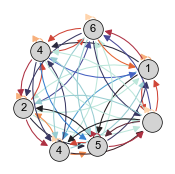

In [21]:

G = nx.DiGraph((w_rec_reduced).T.numpy(), create_using=nx.DiGraph)

# Calculate positions
x =  reduced_net(u).detach().numpy()
x = x.reshape(-1, x.shape[2]).T
x_proj = PCA(n_components = 2).fit_transform(x)
pos = {}
for i in range(x_proj.shape[0]):
    pos[i]= x_proj[i,:]
#pos = nx.spring_layout(G,k=1)
fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1, figure=fig)

ax=fig.add_subplot(gs[0,0])

nx.draw_networkx_nodes(G, pos,cmap=plt.get_cmap('coolwarm'), node_color='lightgray',
                       edgecolors='black',
                       linewidths=.5,
                         node_size=200,
                       alpha=1,
                      ax=ax)

edges,weights = zip(*nx.get_edge_attributes(G,'weight').items())
center= 1 - np.max(weights) / (np.max(weights) + abs(np.min(weights)))
#orig_cmap = matplotlib.cm.coolwarm
orig_cmap = matplotlib.cm.get_cmap('icefire', 20)
#shrunk_cmap = shiftedColorMap(orig_cmap, start=0, midpoint=center, stop=1, name='shrunk')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
nx.draw_networkx_edges(G, pos, width = .75,edge_color=weights,edge_cmap=orig_cmap,connectionstyle="Arc3, rad=.3",arrowsize=10, alpha = 1,ax=ax)
 
nx.draw_networkx_labels(G, pos,{0:'1',1:'2',2:'4',3:'4',4:'5',5:'6'}, font_size=8, font_color="k")
fig.savefig('Figures/circuit.jpg',
    format='jpeg',
    dpi=450,
)

In [39]:
reduced_net.recurrent_layer.bias

Parameter containing:
tensor([0.8484, 0.7995, 0.9589, 0.7728, 0.7199, 0.7741])

<Axes: >

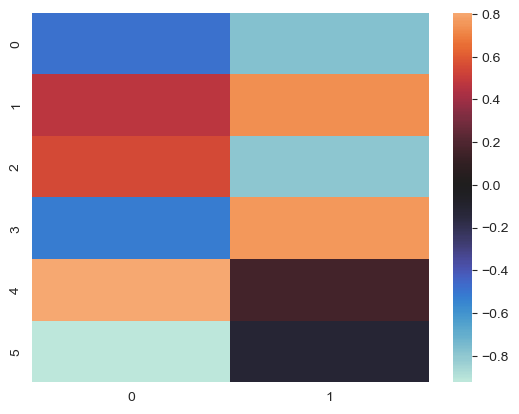

In [44]:
plt.figure()
sns.heatmap(reduced_net.input_layer.weight.data,center=0)

In [45]:
x = reduced_net(u)

In [46]:
x.shape

torch.Size([2500, 75, 6])

<Axes: >

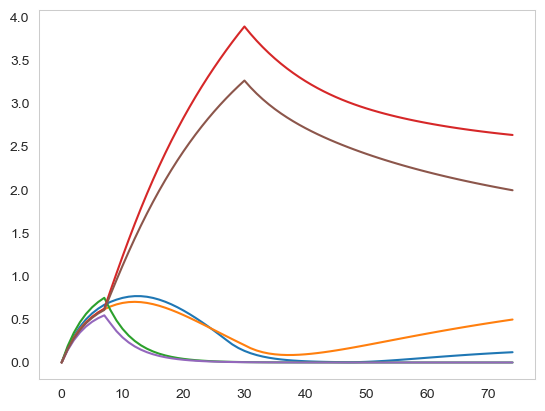

In [56]:
plt.figure()
sns.lineplot(x[4,:,0].detach())
sns.lineplot(x[4,:,1].detach())
sns.lineplot(x[4,:,2].detach())
sns.lineplot(x[4,:,3].detach())
sns.lineplot(x[4,:,4].detach())
sns.lineplot(x[4,:,5].detach())

In [65]:
torch.mean(reduced_net.input_layer(u),dim=  [0,1])

tensor([-0.0030,  0.0029,  0.0034, -0.0032,  0.0049, -0.0057],
       grad_fn=<MeanBackward1>)

In [66]:
torch.mean(reduced_net.recurrent_layer(reduced_net(u)),dim=  [0,1])

tensor([0.8460, 0.7399, 0.9301, 0.8164, 0.6442, 0.7816],
       grad_fn=<MeanBackward1>)

In [67]:
reduced_net.recurrent_layer.bias

Parameter containing:
tensor([0.8484, 0.7995, 0.9589, 0.7728, 0.7199, 0.7741])

<Axes: ylabel='Count'>

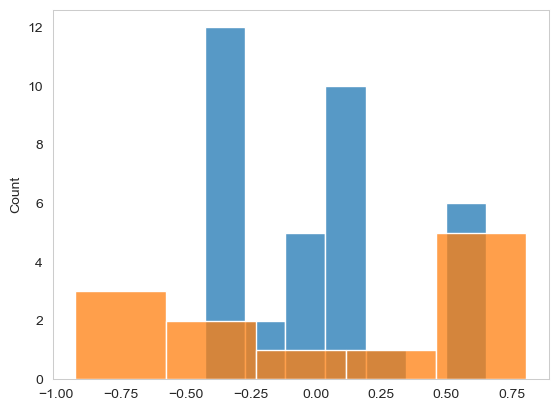

In [70]:
plt.figure()
sns.histplot(reduced_net.recurrent_layer.weight.data.detach().flatten())
sns.histplot(reduced_net.input_layer.weight.data.detach().flatten())

In [72]:
input_noise = torch.sqrt(torch.tensor(2 / 0.2 * 0.1 ** 2)) * torch.empty(u.shape[0], u.shape[1],2).normal_(mean=0,std=1)

In [77]:
inputs = net.input_layer(u+input_noise)

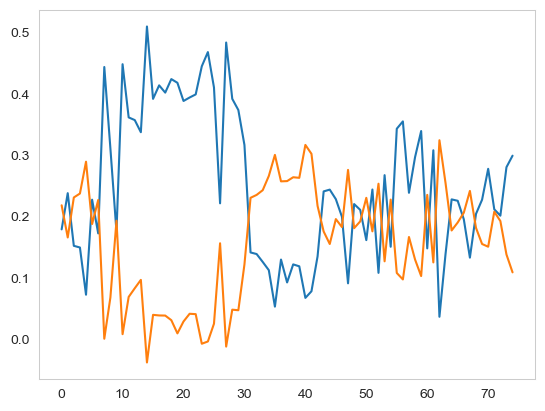

In [79]:
plt.figure()
plt.plot(inputs[0,:,0].detach())
plt.plot(inputs[0,:,1].detach())

In [76]:
reduced_net.input_layer.bias

Parameter containing:
tensor([0., 0., 0., 0., 0., 0.])